# How to build an Explainable AI Analysis Pipeline Using SHAP-IQ#

Going off of the article from: [XAI Analysis Pipeline with SHAP-IQ](https://www-marktechpost-com.cdn.ampproject.org/v/s/www.marktechpost.com/2026/03/01/how-to-build-an-explainable-ai-analysis-pipeline-using-shap-iq-to-understand-feature-importance-interaction-effects-and-model-decision-breakdown/?amp=&amp_gsa=1&amp_js_v=a9&usqp=mq331AQGsAEggAID#amp_tf=From%20%251%24s&aoh=17725779760475&csi=0&referrer=https%3A%2F%2Fwww.google.com&ampshare=https%3A%2F%2Fwww.marktechpost.com%2F2026%2F03%2F01%2Fhow-to-build-an-explainable-ai-analysis-pipeline-using-shap-iq-to-understand-feature-importance-interaction-effects-and-model-decision-breakdown%2F)
<br>
This article highlights importance of using SHAP for Feature Importance, Interaction Effects, and Model Decision Breakdown.

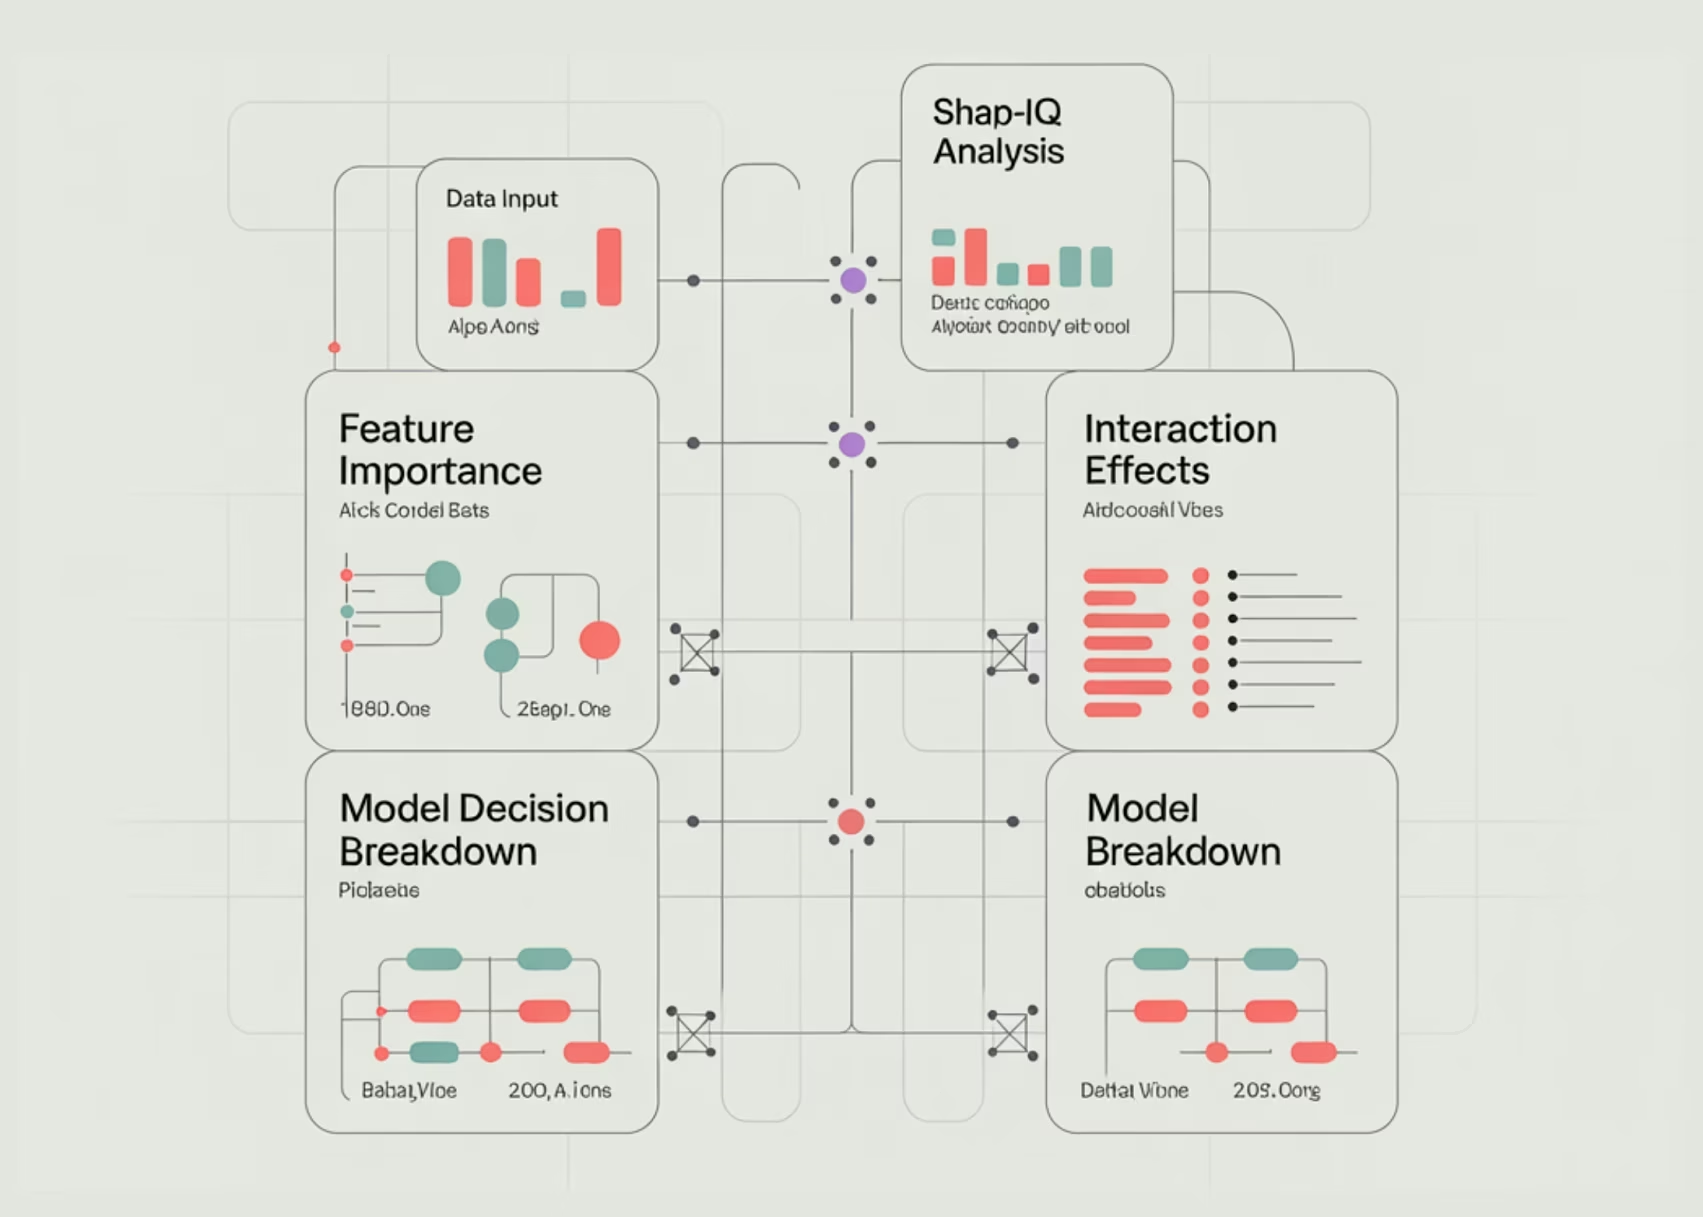


In [2]:
import sys, subprocess, textwrap, numpy as np, pandas as pd


def _pip(*pkgs):
   subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)


_pip("shapiq", "plotly", "pandas", "numpy", "scikit-learn")


import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import shapiq
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split


try:
   pio.renderers.default = "colab"
except Exception:
   pass


RANDOM_STATE = 42
INDEX = "SII"
MAX_ORDER = 2
BUDGET_LOCAL = 512
TOP_K = 10
INSTANCE_I = 24
GLOBAL_ON = True
GLOBAL_N = 40
BUDGET_GLOBAL = 256

In [3]:
def extract_main_effects(iv, feature_names):
   d = iv.dict_values
   vals = [float(d.get((i,), 0.0)) for i in range(len(feature_names))]
   return pd.Series(vals, index=list(feature_names), name="main_effect")


def extract_pair_matrix(iv, feature_names):
   d = iv.dict_values
   n = len(feature_names)
   M = np.zeros((n, n), dtype=float)
   for k, v in d.items():
       if isinstance(k, tuple) and len(k) == 2:
           i, j = k
           M[i, j] = float(v)
           M[j, i] = float(v)
   return pd.DataFrame(M, index=list(feature_names), columns=list(feature_names))


def ascii_bar(series, width=28, top_k=10):
   s = series.abs().sort_values(ascending=False).head(top_k)
   m = float(s.max()) if len(s) else 1.0
   lines = []
   for name, val in s.items():
       n = int((abs(val) / m) * width) if m > 0 else 0
       lines.append(f"{name:>18} | {'█'*n}{' '*(width-n)} | {val:+.6f}")
   return "\n".join(lines)

In [7]:
def plot_local_feature_bar(main_effects, top_k):
    df = main_effects.abs().sort_values(ascending=False).head(top_k).reset_index()
    df.columns = ["feature", "abs_main_effect"]
    fig = px.bar(df, x="abs_main_effect", y="feature", orientation="h", title="Local Feature Importance (|Main Effects|)")
    fig.update_layout(yaxis={"categoryorder": "total ascending"})
    return fig

def plot_local_interaction_heatmap(pair_df, top_features):
    sub = pair_df.loc[top_features, top_features]
    fig = px.imshow(sub.values, x=sub.columns, y=sub.index, aspect="auto", title="Local Pairwise Interaction Importance (values)")
    return fig

def plot_waterfall(baseline, main_effects, top_k):
    contrib = main_effects.copy()
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).head(top_k).index)
    remainder = float(contrib.sum() - top.sum())
    labels = ["baseline"] + list(top.index) + (["others"] if abs(remainder) > 1e-12 else []) + ["prediction"]
    measures = ["absolute"] + ["relative"] * len(top) + (["relative"] if abs(remainder) > 1e-12 else []) + ["total"]
    y = [0.0] + [float(v) for v in top.values] + ([float(remainder)] if abs(remainder) > 1e-12 else []) + [0.0]
    fig = go.Figure(go.Waterfall(x=labels, y=y, measure=measures, orientation="v", connector={"line": {"width": 1}}))
    fig.update_layout(title="Decision Breakdown (Baseline → Prediction via Main Effects)", showlegend=False)
    return fig

In [5]:
def global_summaries(explainer, X_samples, feature_names, budget, seed=123):
   main_abs = np.zeros(len(feature_names), dtype=float)
   pair_abs = np.zeros((len(feature_names), len(feature_names)), dtype=float)
   for t, x in enumerate(X_samples):
       iv = explainer.explain(x, budget=int(budget), random_state=int(seed + t))
       main = extract_main_effects(iv, feature_names).values
       pair = extract_pair_matrix(iv, feature_names).values
       main_abs += np.abs(main)
       pair_abs += np.abs(pair)
   main_abs /= max(1, len(X_samples))
   pair_abs /= max(1, len(X_samples))
   main_df = pd.DataFrame({"feature": feature_names, "mean_abs_main_effect": main_abs}).sort_values("mean_abs_main_effect", ascending=False)
   pair_df = pd.DataFrame(pair_abs, index=feature_names, columns=feature_names)
   return main_df, pair_df


X, y = shapiq.load_california_housing()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

feature_names = list(X_train.columns)
n_features = len(feature_names)


model = RandomForestRegressor(
   n_estimators=400,
   max_depth=max(3, n_features),
   max_features=2/3,
   max_samples=2/3,
   random_state=RANDOM_STATE,
   n_jobs=-1
)
model.fit(X_train.values, y_train.values)


explainer = shapiq.TabularExplainer(
   model=model.predict,
   data=X_train.values,
   index=INDEX,
   max_order=int(MAX_ORDER),
)

In [8]:
INSTANCE_I = int(np.clip(INSTANCE_I, 0, len(X_test)-1))
x = X_test.iloc[INSTANCE_I].values
y_true = float(y_test.iloc[INSTANCE_I])
pred = float(model.predict([x])[0])


iv = explainer.explain(x, budget=int(BUDGET_LOCAL), random_state=0)
baseline = float(getattr(iv, "baseline_value", 0.0))


main_effects = extract_main_effects(iv, feature_names)
pair_df = extract_pair_matrix(iv, feature_names)


print("\n" + "="*90)
print("LOCAL EXPLANATION (single test instance)")
print("="*90)
print(f"Index={INDEX} | max_order={MAX_ORDER} | budget={BUDGET_LOCAL} | instance={INSTANCE_I}")
print(f"Prediction: {pred:.6f} | True: {y_true:.6f} | Baseline (if available): {baseline:.6f}")


print("\nTop main effects (signed):")
display(main_effects.reindex(main_effects.abs().sort_values(ascending=False).head(TOP_K).index).to_frame())


print("\nASCII view (signed main effects, top-k):")
print(ascii_bar(main_effects, top_k=TOP_K))


print("\nTop pairwise interactions by |value| (local):")
pairs = []
for i in range(n_features):
   for j in range(i+1, n_features):
       v = float(pair_df.iat[i, j])
       pairs.append((feature_names[i], feature_names[j], v, abs(v)))
pairs_df = pd.DataFrame(pairs, columns=["feature_i", "feature_j", "interaction", "abs_interaction"]).sort_values("abs_interaction", ascending=False).head(min(25, len(pairs)))
display(pairs_df)


fig1 = plot_local_feature_bar(main_effects, TOP_K)
fig2 = plot_local_interaction_heatmap(pair_df, list(main_effects.abs().sort_values(ascending=False).head(TOP_K).index))
fig3 = plot_waterfall(baseline, main_effects, TOP_K)


fig1.show()
fig2.show()
fig3.show()


if GLOBAL_ON:
   print("\n" + "="*90)
   print("GLOBAL SUMMARIES (sampled over multiple test points)")
   print("="*90)
   GLOBAL_N = int(np.clip(GLOBAL_N, 5, len(X_test)))
   sample = X_test.sample(n=GLOBAL_N, random_state=1).values


   global_main, global_pair = global_summaries(
       explainer=explainer,
       X_samples=sample,
       feature_names=feature_names,
       budget=int(BUDGET_GLOBAL),
       seed=123,
   )


   print(f"Samples={GLOBAL_N} | budget/sample={BUDGET_GLOBAL}")
   print("\nGlobal feature importance (mean |main effect|):")
   display(global_main.head(TOP_K))


   top_feats_global = list(global_main["feature"].head(TOP_K).values)
   sub = global_pair.loc[top_feats_global, top_feats_global]


   figg1 = px.bar(global_main.head(TOP_K), x="mean_abs_main_effect", y="feature", orientation="h", title="Global Feature Importance (mean |main effect|, sampled)")
   figg1.update_layout(yaxis={"categoryorder": "total ascending"})
   figg2 = px.imshow(sub.values, x=sub.columns, y=sub.index, aspect="auto", title="Global Pairwise Interaction Importance (mean |interaction|, sampled)")


   figg1.show()
   figg2.show()


print("\nDone. If you want it faster: lower budgets or GLOBAL_N, or set MAX_ORDER=1.")

c:\Users\JoeDavis\anaconda3\Lib\site-packages\shapiq\approximator\regression\base.py:159: UserWarning:

Not all budget is required due to the border-trick.




LOCAL EXPLANATION (single test instance)
Index=SII | max_order=2 | budget=512 | instance=24
Prediction: 1.772690 | True: 1.621000 | Baseline (if available): 2.070064

Top main effects (signed):


,main_effect
Longitude,-0.260294
Latitude,0.154499
AveOccup,-0.149340
HouseAge,-0.079441
MedInc,0.023261
AveRooms,-0.021006
Population,0.019989
AveBedrms,0.014959



ASCII view (signed main effects, top-k):
         Longitude | ████████████████████████████ | +0.260294
          Latitude | ████████████████             | +0.154499
          AveOccup | ████████████████             | +0.149340
          HouseAge | ████████                     | +0.079441
            MedInc | ██                           | +0.023261
          AveRooms | ██                           | +0.021006
        Population | ██                           | +0.019989
         AveBedrms | █                            | +0.014959

Top pairwise interactions by |value| (local):


,feature_i,feature_j,interaction,abs_interaction
10,HouseAge,AveOccup,0.107119,0.107119
4,MedInc,AveOccup,-0.085049,0.085049
5,MedInc,Latitude,-0.055457,0.055457
0,MedInc,HouseAge,-0.048764,0.048764
27,Latitude,Longitude,-0.043189,0.043189
25,AveOccup,Latitude,-0.033629,0.033629
17,AveRooms,Longitude,-0.028312,0.028312
22,Population,AveOccup,-0.025100,0.025100
2,MedInc,AveBedrms,-0.022822,0.022822
20,AveBedrms,Latitude,-0.022452,0.022452



GLOBAL SUMMARIES (sampled over multiple test points)
Samples=40 | budget/sample=256

Global feature importance (mean |main effect|):


,feature,mean_abs_main_effect
0,MedInc,0.450423
6,Latitude,0.217342
5,AveOccup,0.205067
7,Longitude,0.160958
1,HouseAge,0.079347
2,AveRooms,0.047189
3,AveBedrms,0.014274
4,Population,0.013930



Done. If you want it faster: lower budgets or GLOBAL_N, or set MAX_ORDER=1.
